In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider

def plot_phase(alpha=0.4,beta=0.8,gamma=0.8,delta=0.6):

    x = np.linspace(0,1,1000)

    dx = x*(1-x)*(
        (alpha-gamma)*x +
        (beta-delta)*(1-x)
    )

    plt.figure(figsize=(10,3))

    plt.axhline(0,color='black')

    plt.plot(x,dx,'k',lw=3)

    denom = alpha-gamma+delta-beta

    plt.axvline(0,color='red',lw=3,label='x=0')

    plt.axvline(1,color='blue',lw=3,label='x=1')

    if abs(denom)>1e-10:

        xs = (delta-beta)/denom

        if 0 < xs < 1:

            plt.axvline(
                xs,
                color='green',
                lw=3,
                linestyle='--',
                label=f'x*={xs:.3f}'
            )

    plt.xlabel("Leader fraction x")
    plt.ylabel("dx/dt")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()

interact(
    plot_phase,
    alpha=FloatSlider(value=0.4,min=0,max=1.5,step=0.05),
    beta=FloatSlider(value=0.8,min=0,max=1.5,step=0.05),
    gamma=FloatSlider(value=0.8,min=0,max=1.5,step=0.05),
    delta=FloatSlider(value=0.6,min=0,max=1.5,step=0.05)
);

interactive(children=(FloatSlider(value=0.4, description='alpha', max=1.5, step=0.05), FloatSlider(value=0.8, …

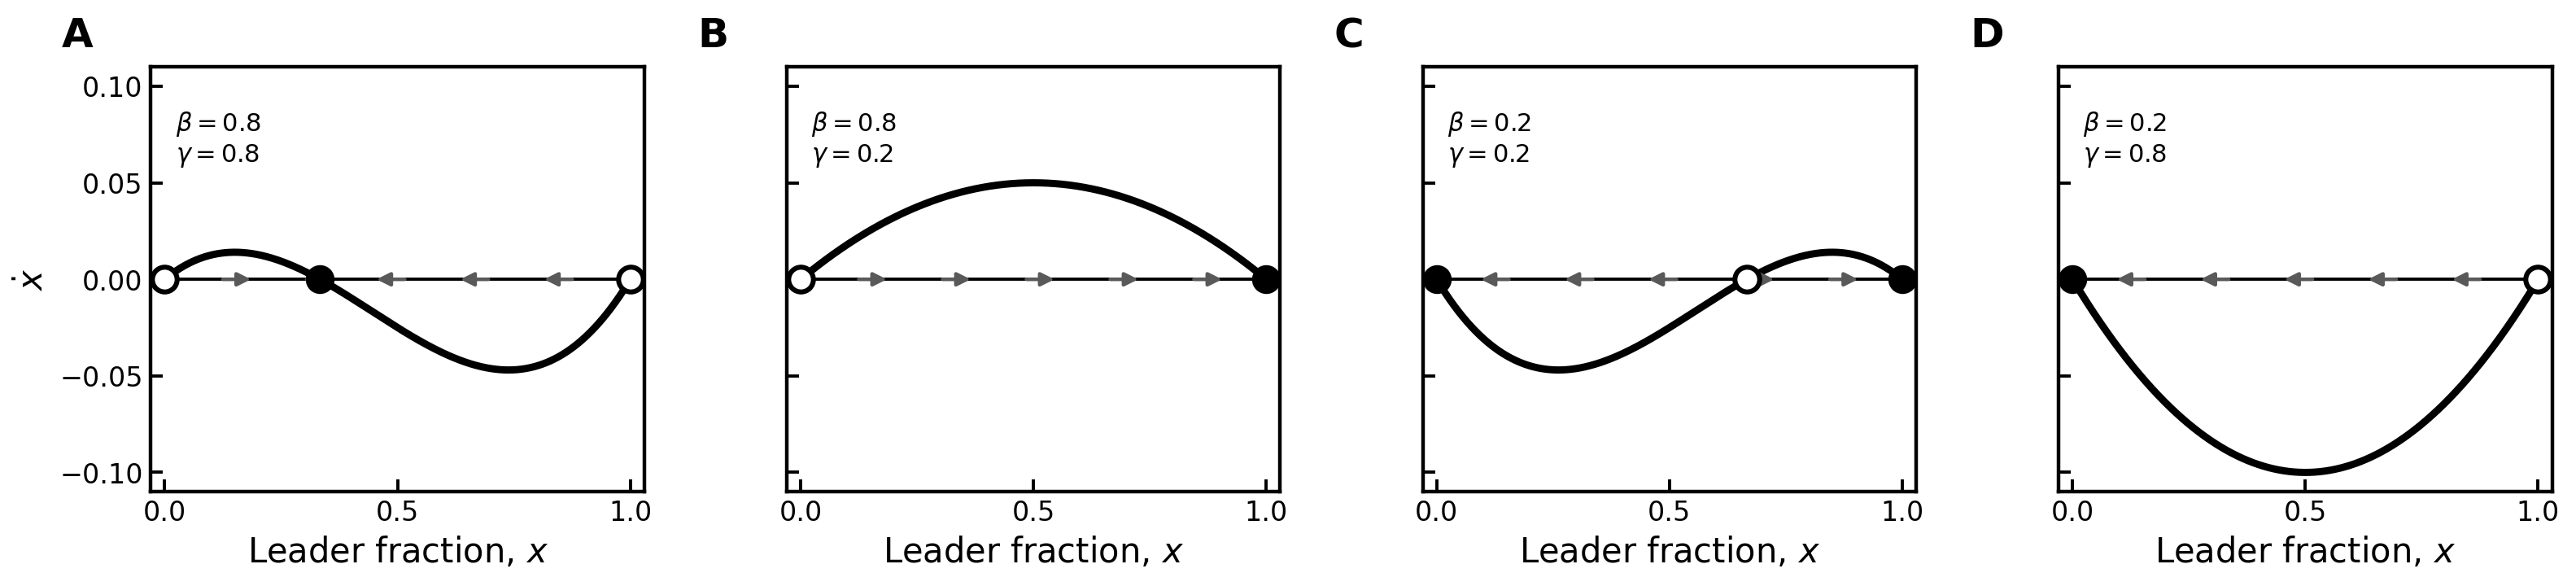

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Publication style
# ============================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.labelsize": 15,
    "axes.titlesize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.linewidth": 1.6,
    "lines.linewidth": 3.0,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 5.5,
    "ytick.major.size": 5.5,
    "xtick.major.width": 1.4,
    "ytick.major.width": 1.4,
    "figure.dpi": 200,
    "savefig.dpi": 600,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# ============================================================
# Model
# ============================================================

def dxdt(x, alpha, beta, gamma, delta):
    return x*(1-x)*((alpha-gamma)*x + (beta-delta)*(1-x))

def fixed_points(alpha, beta, gamma, delta):
    fps = [0.0, 1.0]
    denom = alpha - gamma + delta - beta

    if abs(denom) > 1e-12:
        xs = (delta - beta) / denom
        if 0 < xs < 1:
            fps.append(xs)

    return sorted(fps)

def is_stable(x0, alpha, beta, gamma, delta):
    eps = 1e-5

    if np.isclose(x0, 0):
        return dxdt(eps, alpha, beta, gamma, delta) < 0

    if np.isclose(x0, 1):
        return dxdt(1-eps, alpha, beta, gamma, delta) > 0

    h = 1e-6
    deriv = (
        dxdt(x0+h, alpha, beta, gamma, delta)
        -
        dxdt(x0-h, alpha, beta, gamma, delta)
    ) / (2*h)

    return deriv < 0

# ============================================================
# Parameters
# ============================================================

alpha = 0.4
delta = 0.6

cases = [
    ("A", "Snowdrift",          0.8, 0.8),
    ("B", "Harmony",            0.8, 0.2),
    ("C", "Coordination",       0.2, 0.2),
    ("D", "Prisoner's Dilemma", 0.2, 0.8),
]

x = np.linspace(0, 1, 2000)

# ============================================================
# Plot
# ============================================================

fig, axes = plt.subplots(
    1, 4,
    figsize=(16, 3.8),
    sharey=True
)

for ax, (letter, name, beta, gamma) in zip(axes, cases):

    y = dxdt(x, alpha, beta, gamma, delta)

    # main curve
    ax.plot(x, y, color="black", lw=3.2)

    # zero axis
    ax.axhline(0, color="black", lw=1.4)

    # fixed points
    fps = fixed_points(alpha, beta, gamma, delta)

    for fp in fps:
        stable = is_stable(fp, alpha, beta, gamma, delta)

        if stable:
            ax.scatter(
                fp, 0,
                s=120,
                facecolor="black",
                edgecolor="black",
                linewidth=1.8,
                zorder=6
            )
        else:
            ax.scatter(
                fp, 0,
                s=120,
                facecolor="white",
                edgecolor="black",
                linewidth=2.2,
                zorder=6
            )

    # flow arrows
    arrow_x = np.linspace(0.14, 0.86, 5)

    for xx in arrow_x:
        val = dxdt(xx, alpha, beta, gamma, delta)

        if abs(val) > 1e-6:
            direction = np.sign(val)

            ax.annotate(
                "",
                xy=(xx + 0.055*direction, 0),
                xytext=(xx - 0.025*direction, 0),
                arrowprops=dict(
                    arrowstyle="-|>",
                    lw=1.6,
                    color="0.35",
                    mutation_scale=12
                ),
                zorder=5
            )

    # axes formatting
    ax.set_xlim(-0.03, 1.03)
    ax.set_ylim(-0.11, 0.11)

    ax.set_xticks([0, 0.5, 1])
    ax.set_yticks([-0.10, -0.05, 0, 0.05, 0.10])

    ax.set_xlabel(r"Leader fraction, $x$")


    ax.grid(False)

    # panel letter
    ax.text(
        -0.18, 1.12,
        letter,
        transform=ax.transAxes,
        fontsize=18,
        fontweight="bold",
        va="top",
        ha="left"
    )

    # parameter label
    ax.text(
        0.05, 0.90,
        fr"$\beta={beta:.1f}$" "\n" fr"$\gamma={gamma:.1f}$",
        transform=ax.transAxes,
        fontsize=11,
        va="top",
        ha="left"
    )

axes[0].set_ylabel(r"$\dot{x}$")

# legend
stable_handle = plt.Line2D(
    [0], [0],
    marker="o",
    color="black",
    markerfacecolor="black",
    markeredgecolor="black",
    markersize=8,
    linestyle="None",
    label="Stable"
)

unstable_handle = plt.Line2D(
    [0], [0],
    marker="o",
    color="black",
    markerfacecolor="white",
    markeredgecolor="black",
    markeredgewidth=2,
    markersize=8,
    linestyle="None",
    label="Unstable"
)


plt.tight_layout(w_pad=2.0)
plt.show()